# The demographic drag AI has to cancel out: data and code

This notebook reproduces every chart and every number in the essay. Run it top to bottom, or as a
script with `python story.py`. The first run downloads about 130 MB of public data into `data/raw/`;
after that it runs in seconds. Each figure is saved to `figures/` as PNG and SVG, and every number
the essay quotes is written to `numbers.md` with its source.

**Data:** UN World Population Prospects 2024; World Bank World Development Indicators (GDP per person
employed); US Bureau of Labor Statistics via FRED; Indeed Hiring Lab job postings; Eloundou et al.
(2023) occupational exposure to large language models; published AI productivity forecasts
(`data/ai_estimates.csv`). Sources and caveats are listed in `README.md`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, MultipleLocator

import datasets as ds
import style as st
from facts import Facts

HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
facts = Facts()
NAMES = ds.NAMES
SHORT = {**NAMES, "KOR": "Korea", "USA": "US", "GBR": "Britain"}
LAST = ds.LAST_ESTIMATE_YEAR
FOCUS = list(ds.COUNTRIES)
UN = "UN World Population Prospects 2024"

ind = ds.wpp_indicators()
ages = ds.wpp_broad_ages()
countries = ind[ind.loc_type == "Country/Area"]
print(f"{countries.iso3.nunique()} countries and areas, {ind.year.min()}-{ind.year.max()}")

237 countries and areas, 1950-2101


## 1. Most of humanity now lives below replacement fertility

A total fertility rate (TFR) of about 2.1 children per woman keeps a population stable in the long run,
leaving migration aside. For each year we add up the population of every country whose TFR is below 2.1.
The net reproduction rate (NRR) is the stricter test, because replacement is higher where more children
die young; we report the NRR-based share as a check.

In [2]:
def share_below(col, threshold):
    pop = countries.pop_thousands
    return pop.where(countries[col] < threshold, 0).groupby(countries.year).sum() / pop.groupby(countries.year).sum() * 100


below = share_below("tfr", 2.1)
below_nrr = share_below("nrr", 1.0)
crossed = {iso: int(ind[(ind.iso3 == iso) & (ind.tfr < 2.1)].year.min()) for iso in ("CHN", "IND")}
world = ind[ind.iso3 == ds.WORLD].set_index("year")
india_share = ind[(ind.iso3 == "IND") & (ind.year == LAST)].pop_thousands.item() / world.loc[LAST, "pop_thousands"] * 100

for year in (1975, 1990, 2000, 2010, LAST, 2050, 2100):
    facts(f"share_below_replacement_{year}", below[year], f"% of world population in countries with TFR below 2.1, {year}", UN, "{:.0f}%")
facts(f"share_below_nrr_{LAST}", below_nrr[LAST], f"same, using net reproduction rate below 1, {LAST}", UN, "{:.0f}%")
facts(f"countries_below_2_1_{LAST}", int((countries[countries.year == LAST].tfr < 2.1).sum()),
      f"countries and areas with TFR below 2.1, {LAST} (of {countries[countries.year == LAST].iso3.nunique()})", UN, "{:d}")
facts(f"world_tfr_{LAST}", world.loc[LAST, "tfr"], f"world total fertility rate, {LAST}", UN)
facts("china_below_2_1_since", crossed["CHN"], "first year China's TFR was below 2.1", UN, "{:d}")
facts("india_below_2_1_since", crossed["IND"], "first year India's TFR was below 2.1", UN, "{:d}")
facts(f"india_share_world_pop_{LAST}", india_share, f"India's share of world population, {LAST}", UN, "{:.0f}%")

share_below_replacement_1975                    20%   % of world population in countries with TFR below 2.1, 1975
share_below_replacement_1990                    24%   % of world population in countries with TFR below 2.1, 1990
share_below_replacement_2000                    46%   % of world population in countries with TFR below 2.1, 2000
share_below_replacement_2010                    47%   % of world population in countries with TFR below 2.1, 2010
share_below_replacement_2023                    67%   % of world population in countries with TFR below 2.1, 2023
share_below_replacement_2050                    69%   % of world population in countries with TFR below 2.1, 2050
share_below_replacement_2100                    87%   % of world population in countries with TFR below 2.1, 2100
share_below_nrr_2023                            71%   same, using net reproduction rate below 1, 2023
countries_below_2_1_2023                        130   countries and areas with TFR below 2.1, 2023 (

17.772079886952007

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/01_below_replacement.png')

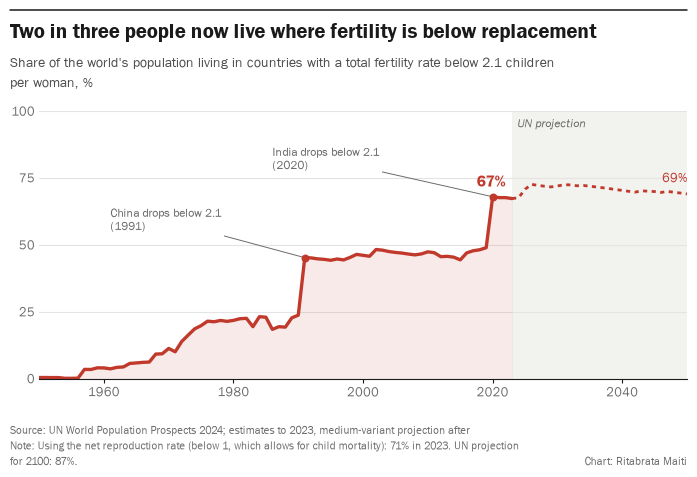

In [3]:
fig, ax = st.new_figure(
    "Two in three people now live where fertility is below replacement",
    "Share of the world's population living in countries with a total fertility rate below 2.1 children per woman, %",
    f"{UN}; estimates to {LAST}, medium-variant projection after",
    note=f"Using the net reproduction rate (below 1, which allows for child mortality): {below_nrr[LAST]:.0f}% in {LAST}. "
         f"UN projection for 2100: {below[2100]:.0f}%.")
ax.set_xlim(1950, 2050)
ax.set_ylim(0, 100)
st.shade_projection(ax, LAST, 2050)
est, proj = below.loc[1950:LAST], below.loc[LAST:2050]
ax.fill_between(est.index, est.values, color=st.RED, alpha=0.10, lw=0)
ax.plot(est.index, est.values, color=st.RED, lw=2.4)
ax.plot(proj.index, proj.values, color=st.RED, lw=2, ls=(0, (1.5, 1.6)))
for iso, (dx, dy) in {"CHN": (-30, 14), "IND": (-34, 14)}.items():
    year = crossed[iso]
    ax.scatter([year], [below[year]], s=22, color=st.RED, zorder=4)
    st.note(ax, f"{NAMES[iso]} drops below 2.1\n({year})", (year, below[year]), (year + dx, below[year] + dy))
ax.text(LAST - 1, below[LAST] + 4.5, f"{below[LAST]:.0f}%", color=st.RED, fontsize=11.5, ha="right", **st.BOLD)
ax.text(2050, below[2050] + 4.5, f"{below[2050]:.0f}%", color=st.RED, fontsize=9.5, ha="right")
ax.yaxis.set_major_locator(MultipleLocator(25))
st.polish(ax)
st.save(fig, "01_below_replacement")

## 2. Fertility rates in the twelve economies

The context chart: total fertility rate by country, UN estimates to 2023.

tfr_2023_kor                                   0.72   total fertility rate, South Korea, 2023
tfr_2023_jpn                                   1.21   total fertility rate, Japan, 2023
tfr_2023_chn                                   1.00   total fertility rate, China, 2023
tfr_2023_ita                                   1.20   total fertility rate, Italy, 2023
tfr_2023_esp                                   1.21   total fertility rate, Spain, 2023
tfr_2023_deu                                   1.44   total fertility rate, Germany, 2023
tfr_2023_fra                                   1.64   total fertility rate, France, 2023
tfr_2023_gbr                                   1.56   total fertility rate, Britain, 2023
tfr_2023_usa                                   1.62   total fertility rate, United States, 2023
tfr_2023_bra                                   1.62   total fertility rate, Brazil, 2023
tfr_2023_ind                                   1.98   total fertility rate, India, 2023
tfr_2023_nga

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/02_fertility_rates.png')

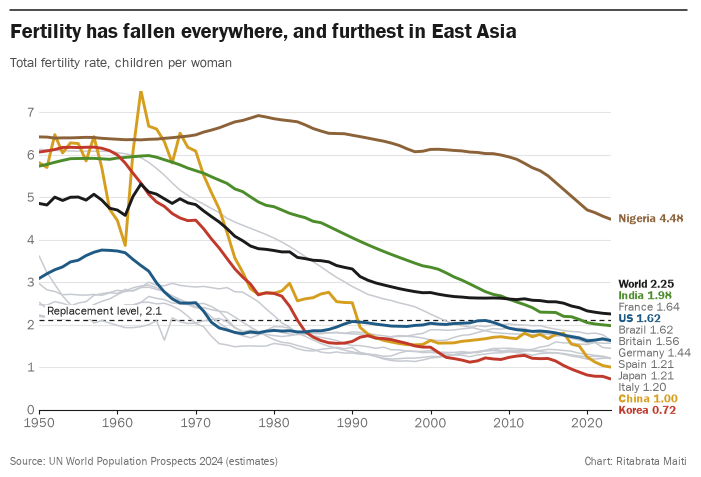

In [4]:
tfr = ind[ind.iso3.isin(FOCUS + [ds.WORLD]) & (ind.year <= LAST)].pivot(index="year", columns="iso3", values="tfr")
for iso in FOCUS + [ds.WORLD]:
    facts(f"tfr_{LAST}_{iso.lower()}", tfr.loc[LAST, iso], f"total fertility rate, {NAMES[iso]}, {LAST}", UN)
facts("tfr_1960_kor", tfr.loc[1960, "KOR"], "total fertility rate, South Korea, 1960", UN)
wb_tfr = ds.worldbank("SP.DYN.TFRT.IN", 2020, 2024)
kor_2024 = wb_tfr[(wb_tfr.iso3 == "KOR") & (wb_tfr.year == 2024)].value
if len(kor_2024):
    facts("tfr_2024_kor_worldbank", kor_2024.item(), "total fertility rate, South Korea, 2024 (latest official)", "World Bank WDI")

HIGHLIGHT = ["KOR", "CHN", "IND", "USA", "NGA", ds.WORLD]
fig, ax = st.new_figure(
    "Fertility has fallen everywhere, and furthest in East Asia",
    "Total fertility rate, children per woman",
    f"{UN} (estimates)",
    right=0.86)
ax.set_xlim(1950, LAST)
ax.set_ylim(0, 7.5)
ax.axhline(2.1, color=st.INK, lw=0.9, ls=(0, (4, 3)), zorder=1)
ax.text(1951, 2.18, "Replacement level, 2.1", fontsize=8.5, color=st.INK, va="bottom", bbox=st.PLATE, zorder=5)
for iso in tfr.columns:
    hot = iso in HIGHLIGHT
    ax.plot(tfr.index, tfr[iso], color=st.COUNTRY_COLORS[iso] if hot else st.CONTEXT, lw=2.1 if hot else 1.1,
            zorder=3 if hot else 2)
st.label_ends(ax, [{"y": tfr.loc[LAST, iso], "text": f"{SHORT[iso]} {tfr.loc[LAST, iso]:.2f}",
                    "color": st.COUNTRY_COLORS[iso] if iso in HIGHLIGHT else st.MUTED, "bold": iso in HIGHLIGHT}
                   for iso in tfr.columns], LAST + 1, gap=0.27, fontsize=8.6)
st.polish(ax)
st.save(fig, "02_fertility_rates")

## 3. Peak workers

Working-age population (15-64), indexed to its own peak. Years after 2023 are the UN's medium-variant
projection, which already assumes some recovery in fertility and continued migration.

peak_workers_year_ita                          1992   year the 15-64 population peaks, Italy
workers_2050_vs_peak_ita                       -31%   15-64 population in 2050 vs its peak, Italy
workers_2025_to_2050_ita                       -27%   change in the 15-64 population from 2025 to 2050, Italy
peak_workers_year_jpn                          1995   year the 15-64 population peaks, Japan
workers_2050_vs_peak_jpn                       -38%   15-64 population in 2050 vs its peak, Japan
workers_2025_to_2050_jpn                       -25%   change in the 15-64 population from 2025 to 2050, Japan
peak_workers_year_deu                          1997   year the 15-64 population peaks, Germany
workers_2050_vs_peak_deu                       -21%   15-64 population in 2050 vs its peak, Germany
workers_2025_to_2050_deu                       -16%   change in the 15-64 population from 2025 to 2050, Germany
peak_workers_year_esp                          2009   year the 15-64 population peaks, Spai

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/03_peak_workers.png')

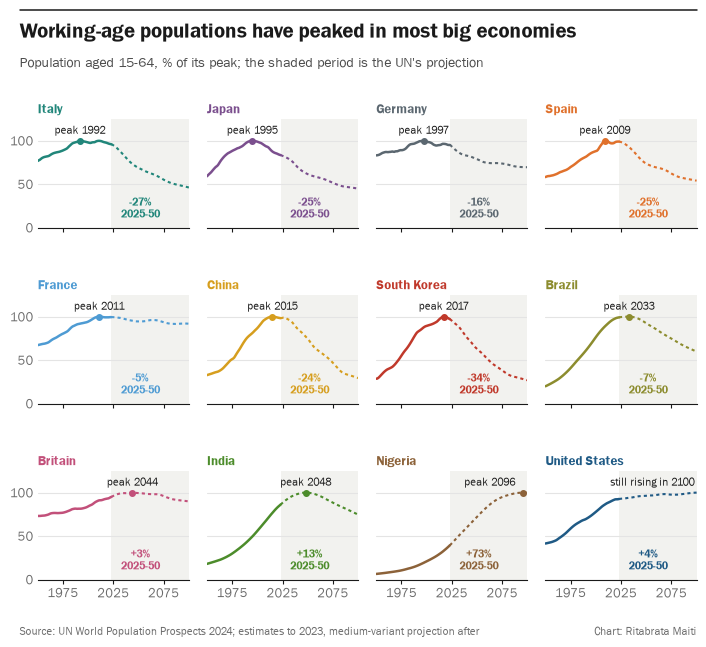

In [5]:
work = ages[ages.iso3.isin(FOCUS)].pivot(index="year", columns="iso3", values="pop_15_64")
peaks = work.idxmax()
order = peaks.sort_values().index.tolist()
for iso in order:
    facts(f"peak_workers_year_{iso.lower()}", int(peaks[iso]), f"year the 15-64 population peaks, {NAMES[iso]}", UN, "{:d}")
    facts(f"workers_2050_vs_peak_{iso.lower()}", (work.loc[2050, iso] / work[iso].max() - 1) * 100,
          f"15-64 population in 2050 vs its peak, {NAMES[iso]}", UN, "{:+.0f}%")
    facts(f"workers_2025_to_2050_{iso.lower()}", (work.loc[2050, iso] / work.loc[2025, iso] - 1) * 100,
          f"change in the 15-64 population from 2025 to 2050, {NAMES[iso]}", UN, "{:+.0f}%")
facts("china_workers_lost_peak_to_2050_m", (work["CHN"].max() - work.loc[2050, "CHN"]) / 1000,
      "fall in China's 15-64 population from its peak to 2050, millions", UN, "{:.0f}m")

fig, axes = st.new_figure(
    "Working-age populations have peaked in most big economies",
    "Population aged 15-64, % of its peak; the shaded period is the UN's projection",
    f"{UN}; estimates to {LAST}, medium-variant projection after",
    nrows=3, ncols=4, height=6.5, sharex=True, sharey=True, hspace=0.62, wspace=0.12, left=0.06, top_pad=0.42)
for ax, iso in zip(axes.flat, order):
    series = work[iso] / work[iso].max() * 100
    color = st.COUNTRY_COLORS[iso]
    ax.axvspan(LAST, 2100, color=st.SHADE, lw=0, zorder=0)
    ax.plot(series.loc[:LAST].index, series.loc[:LAST], color=color, lw=1.8)
    ax.plot(series.loc[LAST:].index, series.loc[LAST:], color=color, lw=1.5, ls=(0, (1.5, 1.5)))
    peak = int(peaks[iso])
    if peak < 2100:
        ax.scatter([peak], [100], s=16, color=color, zorder=4)
        ax.text(min(peak, 2088), 108, f"peak {peak}", ha="center" if peak < 2088 else "right", fontsize=7.8, color=st.INK)
    else:
        ax.text(2098, 108, "still rising in 2100", ha="right", fontsize=7.8, color=st.INK)
    change = (work.loc[2050, iso] / work.loc[2025, iso] - 1) * 100
    ax.text(2052, 22, f"{change:+.0f}%\n2025-50", ha="center", va="center", fontsize=7.6, color=color, **st.BOLD)
    st.panel_title(ax, NAMES[iso], color=color, size=9.5)
    ax.set_xlim(1950, 2100)
    ax.set_ylim(0, 125)
    ax.set_xticks([1975, 2025, 2075])
    ax.yaxis.set_major_locator(MultipleLocator(50))
    st.polish(ax)
st.save(fig, "03_peak_workers")

## 4. Workers per retiree

People aged 20-64 for every person aged 65 and over (the "potential support ratio").

support_1990_kor                              12.06   people aged 20-64 per person 65+, South Korea, 1990
support_2025_kor                               3.20   people aged 20-64 per person 65+, South Korea, 2025
support_2050_kor                               1.25   people aged 20-64 per person 65+, South Korea, 2050
support_1990_jpn                               5.06   people aged 20-64 per person 65+, Japan, 1990
support_2025_jpn                               1.81   people aged 20-64 per person 65+, Japan, 2025
support_2050_jpn                               1.27   people aged 20-64 per person 65+, Japan, 2050
support_1990_chn                              10.32   people aged 20-64 per person 65+, China, 1990
support_2025_chn                               4.27   people aged 20-64 per person 65+, China, 2025
support_2050_chn                               1.81   people aged 20-64 per person 65+, China, 2050
support_1990_ita                               4.07   people aged 20-64 per person

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/04_workers_per_retiree.png')

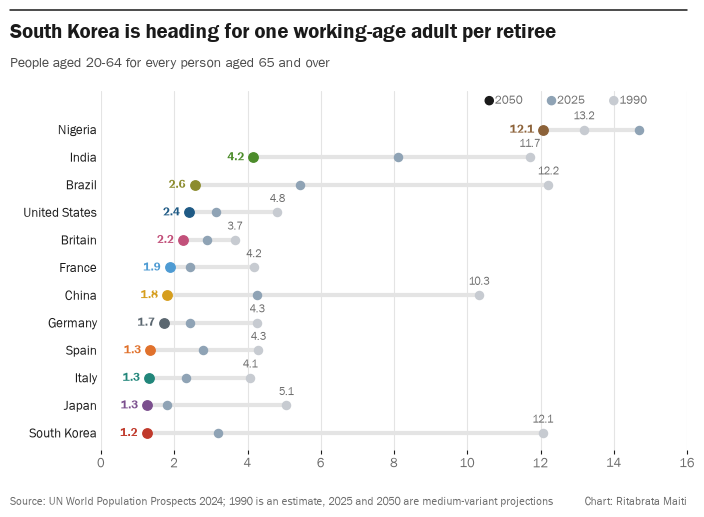

In [6]:
support = ages[ages.iso3.isin(FOCUS)].pivot(index="year", columns="iso3", values="support_20_64")
for iso in FOCUS:
    for year in (1990, 2025, 2050):
        facts(f"support_{year}_{iso.lower()}", support.loc[year, iso], f"people aged 20-64 per person 65+, {NAMES[iso]}, {year}", UN, "{:.2f}")

rows = support.loc[2050].sort_values(ascending=False).index.tolist()
fig, ax = st.new_figure(
    "South Korea is heading for one working-age adult per retiree",
    "People aged 20-64 for every person aged 65 and over",
    f"{UN}; 1990 is an estimate, 2025 and 2050 are medium-variant projections",
    height=5.2, left=0.16)
for i, iso in enumerate(rows):
    v90, v25, v50 = support.loc[[1990, 2025, 2050], iso]
    ax.plot([min(v90, v25, v50), max(v90, v25, v50)], [i, i], color=st.GRID, lw=3, zorder=1, solid_capstyle="round")
    ax.scatter([v90], [i], s=34, color=st.CONTEXT, zorder=3)
    ax.scatter([v25], [i], s=34, color="#8FA3B5", zorder=3)
    ax.scatter([v50], [i], s=46, color=st.COUNTRY_COLORS[iso], zorder=4)
    ax.text(v50 - 0.25, i, f"{v50:.1f}", ha="right", va="center", fontsize=8.5, color=st.COUNTRY_COLORS[iso], **st.BOLD)
    ax.text(v90, i - 0.3, f"{v90:.1f}", ha="center", va="bottom", fontsize=7.8, color=st.MUTED)
ax.set_yticks(range(len(rows)), [NAMES[iso] for iso in rows])
ax.set_ylim(len(rows) - 0.4, -1.4)
ax.set_xlim(0, 16)
legend_y = -1.05
ax.scatter([10.6, 12.3, 14.0], [legend_y] * 3, s=34, color=[st.INK, "#8FA3B5", st.CONTEXT], zorder=4)
for x, label in ((10.75, "2050"), (12.45, "2025"), (14.15, "1990")):
    ax.text(x, legend_y, label, va="center", fontsize=8.5, color=st.MUTED)
st.polish(ax, grid="x", bottom=False)
ax.tick_params(axis="y", labelsize=9.2, labelcolor=st.INK)
st.save(fig, "04_workers_per_retiree")

## 5. The demographic drag

GDP per person = (GDP per worker) x (workers per working-age person) x (working-age share of the population).
Hold the middle term fixed and the change in the last one is the *demographic drag*: how much faster or slower
GDP per person grows than output per worker, purely because the age structure changes. We compute it as the
annualised log change in the 15-64 share between 2025 and 2050 (UN medium variant), and compare it with growth
in GDP per person employed over 2014-24 (World Bank, constant 2021 PPP dollars). Two sensitivity checks:
working ages 20-64 throughout, and a "work to 70" case in which the 2050 working ages are 20-69 instead of 20-64.

In [7]:
def annual_log_change(numer_2025, numer_2050, y0=2025, y1=2050):
    a = ages.set_index(["iso3", "year"])
    return 100 * np.log((a.xs(y1, level="year")[numer_2050] / a.xs(y1, level="year").pop_total)
                        / (a.xs(y0, level="year")[numer_2025] / a.xs(y0, level="year").pop_total)) / (y1 - y0)


drag_all = annual_log_change("pop_15_64", "pop_15_64")
drag_2064 = annual_log_change("pop_20_64", "pop_20_64")
drag_work70 = annual_log_change("pop_20_64", "pop_20_69")
prod = ds.worldbank("SL.GDP.PCAP.EM.KD", 1991, 2024).pivot(index="year", columns="iso3", values="value")
growth_1424 = 100 * np.log(prod.loc[2024] / prod.loc[2014]) / 10
growth_0019 = 100 * np.log(prod.loc[2019] / prod.loc[2000]) / 19

drag = pd.DataFrame({"drag": drag_all, "drag_20_64": drag_2064, "drag_work70": drag_work70}).loc[FOCUS + [ds.WORLD]]
drag["productivity_2014_24"] = growth_1424
drag["productivity_2000_19"] = growth_0019
drag["left_for_gdp_per_person"] = drag.productivity_2014_24 + drag.drag
drag["left_if_work70"] = drag.productivity_2014_24 + drag.drag_work70
drag.round(3).to_csv(ds.PROCESSED / "demographic_drag.csv")
for iso in FOCUS + [ds.WORLD]:
    r = drag.loc[iso]
    facts(f"drag_{iso.lower()}", r.drag, f"demographic drag on GDP per person, {NAMES[iso]}, 2025-50, pp a year", f"{UN}; author's calculation", "{:+.2f}")
    facts(f"drag_work70_{iso.lower()}", r.drag_work70, f"drag if working ages extend to 69 by 2050, {NAMES[iso]}, pp a year", f"{UN}; author's calculation", "{:+.2f}")
    facts(f"productivity_2014_24_{iso.lower()}", r.productivity_2014_24, f"growth in GDP per person employed, {NAMES[iso]}, 2014-24, % a year", "World Bank WDI", "{:+.2f}")
    facts(f"left_{iso.lower()}", r.left_for_gdp_per_person, f"GDP per person growth if productivity repeats 2014-24, {NAMES[iso]}, % a year", "author's calculation", "{:+.2f}")

everyone = ages[ages.loc_type == "Country/Area"].set_index(["iso3", "year"])
big = everyone.xs(2025, level="year").pop_total
big = big[big > 5000].index
ranking = (100 * np.log(everyone.xs(2050, level="year").loc[big, "share_15_64"]
                        / everyone.xs(2025, level="year").loc[big, "share_15_64"]) / 25).sort_values()
ranking.round(3).rename("drag").to_csv(ds.PROCESSED / "drag_ranking_over_5m.csv")
facts("countries_over_5m", len(big), "countries and areas with more than 5m people in 2025", UN, "{:d}")
facts("kor_drag_rank", int(ranking.index.get_loc("KOR")) + 1, "South Korea's rank by size of drag among them (1 = largest)", f"{UN}; author's calculation", "{:d}")
facts("countries_drag_over_half_point", int((ranking < -0.5).sum()), "of those, countries with a drag larger than 0.5 pp a year", f"{UN}; author's calculation", "{:d}")

drag_kor                                      -1.12   demographic drag on GDP per person, South Korea, 2025-50, pp a year
drag_work70_kor                               -0.49   drag if working ages extend to 69 by 2050, South Korea, pp a year
productivity_2014_24_kor                      +1.50   growth in GDP per person employed, South Korea, 2014-24, % a year
left_kor                                      +0.38   GDP per person growth if productivity repeats 2014-24, South Korea, % a year
drag_jpn                                      -0.55   demographic drag on GDP per person, Japan, 2025-50, pp a year
drag_work70_jpn                               -0.02   drag if working ages extend to 69 by 2050, Japan, pp a year
productivity_2014_24_jpn                      -0.10   growth in GDP per person employed, Japan, 2014-24, % a year
left_jpn                                      -0.64   GDP per person growth if productivity repeats 2014-24, Japan, % a year
drag_chn                              

16

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/05_demographic_drag.png')

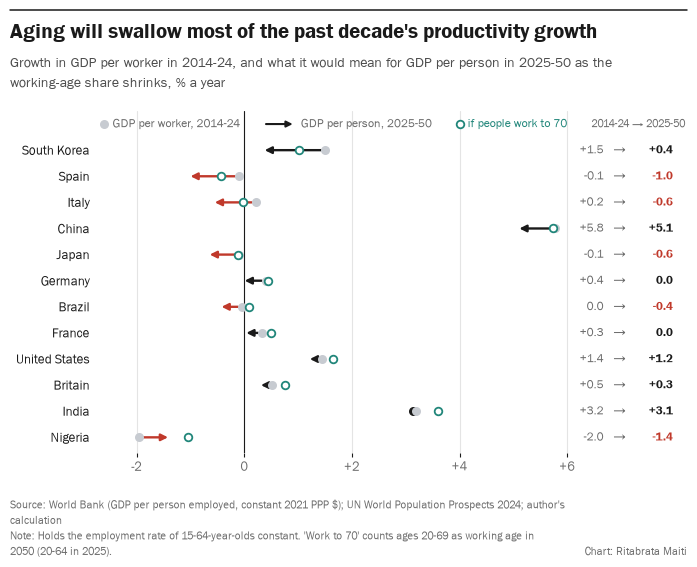

In [8]:
def signed(v):
    return "0.0" if abs(v) < 0.05 else f"{v:+.1f}"


rows = drag.loc[FOCUS].sort_values("drag").index.tolist()
fig, ax = st.new_figure(
    "Aging will swallow most of the past decade's productivity growth",
    "Growth in GDP per worker in 2014-24, and what it would mean for GDP per person in 2025-50 as the working-age "
    "share shrinks, % a year",
    f"World Bank (GDP per person employed, constant 2021 PPP $); {UN}; author's calculation",
    note="Holds the employment rate of 15-64-year-olds constant. 'Work to 70' counts ages 20-69 as working age in "
         "2050 (20-64 in 2025).",
    height=5.7, left=0.15, right=0.83)
for i, iso in enumerate(rows):
    r = drag.loc[iso]
    start, end, alt = r.productivity_2014_24, r.left_for_gdp_per_person, r.left_if_work70
    color = st.RED if end < 0 else st.INK
    if abs(end - start) > 0.12:
        ax.annotate("", xy=(end, i), xytext=(start, i),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.7, shrinkA=3, shrinkB=0, mutation_scale=10))
    else:
        ax.scatter([end], [i], s=30, color=color, zorder=3)
    ax.scatter([start], [i], s=30, color=st.CONTEXT, zorder=3)
    ax.scatter([alt], [i], s=30, facecolor="white", edgecolor=st.TEAL, lw=1.3, zorder=4)
    ax.text(1.03, i, signed(start), transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=8.8,
            color=st.MUTED)
    ax.text(1.05, i, "\u2192", transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=8.8, color=st.MUTED)
    ax.text(1.17, i, signed(end), transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=8.8,
            color=color, **st.BOLD)
ax.text(1.10, -1.0, "2014-24 \u2192 2025-50", transform=ax.get_yaxis_transform(), ha="center", va="center",
        fontsize=8, color=st.MUTED)
ax.axvline(0, color=st.INK, lw=0.8)
ax.set_yticks(range(len(rows)), [NAMES[iso] for iso in rows])
ax.set_ylim(len(rows) - 0.4, -1.5)
ax.set_xlim(-2.8, 6.4)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}" if v else "0"))
key_y = -1.0
ax.scatter([-2.6], [key_y], s=30, color=st.CONTEXT)
ax.text(-2.45, key_y, "GDP per worker, 2014-24", va="center", fontsize=8.3, color=st.MUTED)
ax.annotate("", xy=(0.95, key_y), xytext=(0.35, key_y),
            arrowprops=dict(arrowstyle="-|>", color=st.INK, lw=1.5, mutation_scale=9))
ax.text(1.05, key_y, "GDP per person, 2025-50", va="center", fontsize=8.3, color=st.MUTED)
ax.scatter([4.0], [key_y], s=30, facecolor="white", edgecolor=st.TEAL, lw=1.3)
ax.text(4.15, key_y, "if people work to 70", va="center", fontsize=8.3, color=st.TEAL)
st.polish(ax, grid="x", bottom=False)
ax.tick_params(axis="y", labelsize=9.2, labelcolor=st.INK)
st.save(fig, "05_demographic_drag")

## 6. The size of the hole vs the size of the hoped-for fix

Published forecasts of AI's boost to annual productivity growth (`data/ai_estimates.csv`, with sources and
conversions), against each country's demographic drag. Most forecasts are for the United States; the OECD
expects similar but somewhat smaller gains elsewhere because adoption is slower.

ai_acemoglu_high                               0.11   AI productivity forecast, Acemoglu (2024), upper end, pp a year (labour productivity (converted from TFP), US)
ai_penn_wharton_high                           0.20   AI productivity forecast, Penn Wharton (2025), upper end, pp a year (productivity, US)
ai_mckinsey_high                               0.60   AI productivity forecast, McKinsey (2023), upper end, pp a year (labour productivity, world)
ai_oecd_high                                   0.90   AI productivity forecast, OECD (2024), upper end, pp a year (labour productivity, US (others somewhat lower))
ai_aghion_bunel_high                           1.30   AI productivity forecast, Aghion & Bunel (2024), upper end, pp a year (aggregate productivity, not country-specific)
ai_goldman_sachs_high                          1.50   AI productivity forecast, Goldman Sachs (2023), upper end, pp a year (labour productivity, US)
forecasts_covering_korea                          2   forecasts

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/06_ai_vs_drag.png')

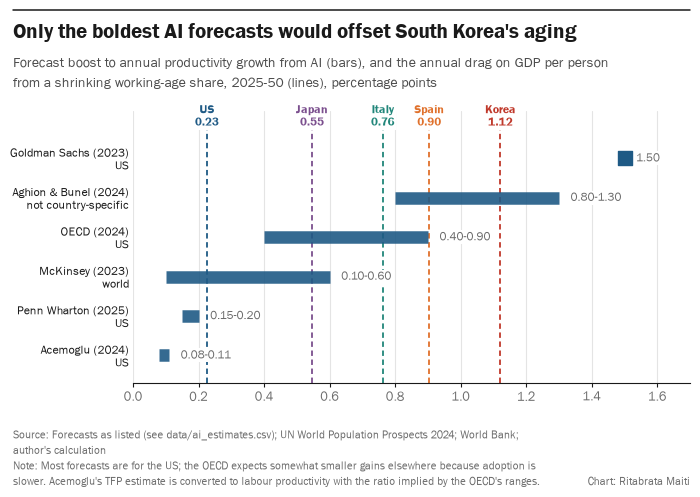

In [9]:
ai = pd.read_csv(HERE / "data" / "ai_estimates.csv").sort_values(["high_pp", "low_pp"]).reset_index(drop=True)
for r in ai.itertuples():
    facts(f"ai_{r.label.split(' (')[0].lower().replace(' & ', '_').replace(' ', '_')}_high", r.high_pp,
          f"AI productivity forecast, {r.label}, upper end, pp a year ({r.measure}, {r.geography})", r.url, "{:.2f}")
lines = ["KOR", "ESP", "ITA", "JPN", "USA"]
covered = {iso: ai[ai.high_pp >= -drag.loc[iso, "drag"]].label.tolist() for iso in lines}
facts("forecasts_covering_korea", len(covered["KOR"]), f"forecasts (of {len(ai)}) whose upper end covers South Korea's drag", "author's calculation", "{:d}")
facts("forecasts_covering_japan", len(covered["JPN"]), f"forecasts (of {len(ai)}) whose upper end covers Japan's drag", "author's calculation", "{:d}")
facts("forecasts_covering_us", len(covered["USA"]), f"forecasts (of {len(ai)}) whose upper end covers the US drag", "author's calculation", "{:d}")

fig, ax = st.new_figure(
    "Only the boldest AI forecasts would offset South Korea's aging",
    "Forecast boost to annual productivity growth from AI (bars), and the annual drag on GDP per person from a "
    "shrinking working-age share, 2025-50 (lines), percentage points",
    f"Forecasts as listed (see data/ai_estimates.csv); {UN}; World Bank; author's calculation",
    note="Most forecasts are for the US; the OECD expects somewhat smaller gains elsewhere because adoption is slower. "
         "Acemoglu's TFP estimate is converted to labour productivity with the ratio implied by the OECD's ranges.",
    height=5.0, left=0.2)
for i, r in enumerate(ai.itertuples()):
    if r.high_pp > r.low_pp:
        ax.plot([r.low_pp, r.high_pp], [i, i], color=st.BLUE, lw=9, solid_capstyle="butt", alpha=0.9, zorder=3)
    else:
        ax.scatter([r.low_pp], [i], s=90, color=st.BLUE, zorder=3, marker="s")
    text = f"{r.low_pp:.2f}-{r.high_pp:.2f}" if r.high_pp > r.low_pp else f"{r.high_pp:.2f}"
    ax.text(r.high_pp + 0.035, i, text, va="center", fontsize=8.3, color=st.MUTED, bbox=st.PLATE, zorder=4)
ax.set_yticks(range(len(ai)), [f"{r.label}\n{r.geography.split(' (')[0]}" for r in ai.itertuples()])
ax.set_ylim(-0.7, len(ai) + 0.2)
ax.set_xlim(0, 1.7)
for iso in lines:
    v = -drag.loc[iso, "drag"]
    ax.axvline(v, color=st.COUNTRY_COLORS[iso], lw=1.3, ls=(0, (3, 2)), zorder=2)
    ax.text(v, len(ai) - 0.25, f"{SHORT[iso]}\n{v:.2f}", ha="center", va="bottom", fontsize=8.3,
            color=st.COUNTRY_COLORS[iso], bbox=st.PLATE, zorder=5, **st.BOLD)
st.polish(ax, grid="x", bottom=True)
ax.tick_params(axis="y", labelsize=8.6, labelcolor=st.INK)
st.save(fig, "06_ai_vs_drag")

## 7. Young graduates

US unemployment rate for 20-24-year-olds with at least a bachelor's degree, against all graduates aged 25 and
over (BLS Current Population Survey via FRED; 12-month moving averages because the young-graduate series is
noisy). The comparison asks whether young graduates are doing worse than graduates in general.

young_grad_unemployment_latest                 6.9%   unemployment, graduates aged 20-24, 12-month average to Sep 2026, %
young_grad_unemployment_2019                   5.1%   same, 12 months to Dec 2019, %
older_grad_unemployment_latest                 3.0%   unemployment, graduates aged 25+, 12-month average to Sep 2026, %
older_grad_unemployment_2019                   2.2%   same, 12 months to Dec 2019, %
young_grad_unemployment_last_this_high         2021   last year (before 2024) the young-graduate rate was this high
young_to_older_ratio_2001_19                   2.0x   young-graduate rate divided by older-graduate rate, average 2001-19
young_to_older_ratio_latest                    2.3x   same, latest 12 months
age20_24_unemployment_latest                   9.9%   unemployment, all 20-24-year-olds, Sep 2026, %


WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/07_young_graduates.png')

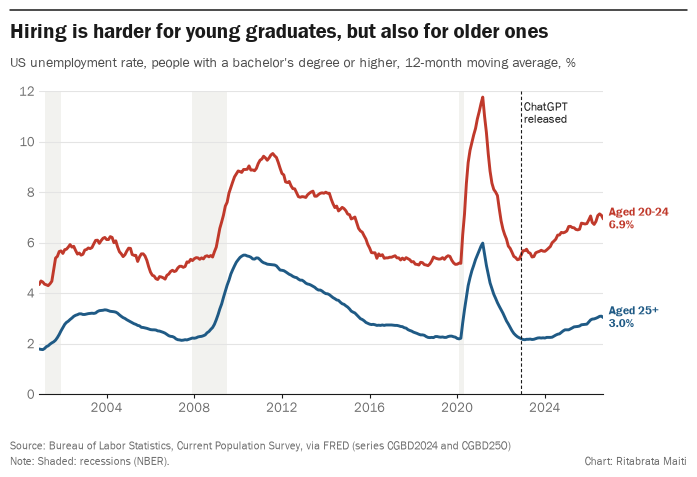

In [10]:
fred = ds.fred(["CGBD2024", "CGBD25O", "LNS14024887", "LNS14000060"]).pivot(index="date", columns="series", values="value")
avg = fred.rolling(12).mean().dropna()
latest = avg.index.max()
young, older = avg.CGBD2024, avg.CGBD25O
higher_before = young[(young >= young.iloc[-1]) & (young.index < "2024-01-01")]
since = higher_before.index.max().year if len(higher_before) else None
ratio = young / older
facts("young_grad_unemployment_latest", young.iloc[-1], f"unemployment, graduates aged 20-24, 12-month average to {latest:%b %Y}, %", "BLS CPS via FRED (CGBD2024)", "{:.1f}%")
facts("young_grad_unemployment_2019", young["2019-12-01"], "same, 12 months to Dec 2019, %", "BLS CPS via FRED (CGBD2024)", "{:.1f}%")
facts("older_grad_unemployment_latest", older.iloc[-1], f"unemployment, graduates aged 25+, 12-month average to {latest:%b %Y}, %", "BLS CPS via FRED (CGBD25O)", "{:.1f}%")
facts("older_grad_unemployment_2019", older["2019-12-01"], "same, 12 months to Dec 2019, %", "BLS CPS via FRED (CGBD25O)", "{:.1f}%")
facts("young_grad_unemployment_last_this_high", since or 0, "last year (before 2024) the young-graduate rate was this high", "BLS CPS via FRED", "{:d}")
facts("young_to_older_ratio_2001_19", ratio["2001":"2019"].mean(), "young-graduate rate divided by older-graduate rate, average 2001-19", "BLS CPS via FRED", "{:.1f}x")
facts("young_to_older_ratio_latest", ratio.iloc[-1], "same, latest 12 months", "BLS CPS via FRED", "{:.1f}x")
facts("age20_24_unemployment_latest", fred.LNS14024887.iloc[-1], f"unemployment, all 20-24-year-olds, {fred.index.max():%b %Y}, %", "BLS CPS via FRED (LNS14024887)", "{:.1f}%")

fig, ax = st.new_figure(
    "Hiring is harder for young graduates, but also for older ones",
    "US unemployment rate, people with a bachelor's degree or higher, 12-month moving average, %",
    "Bureau of Labor Statistics, Current Population Survey, via FRED (series CGBD2024 and CGBD25O)",
    note="Shaded: recessions (NBER).", right=0.85)
for start, end in (("2001-03-01", "2001-11-30"), ("2007-12-01", "2009-06-30"), ("2020-02-01", "2020-04-30")):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=st.SHADE, lw=0, zorder=0)
ax.plot(young.index, young, color=st.RED, lw=2.1)
ax.plot(older.index, older, color=st.BLUE, lw=2.1)
chatgpt = pd.Timestamp("2022-11-30")
ax.axvline(chatgpt, color=st.INK, lw=0.8, ls=(0, (3, 2)))
ax.set_ylim(0, 12)
ax.text(chatgpt + pd.Timedelta(days=45), 11.6, "ChatGPT\nreleased", ha="left", va="top", fontsize=8.3, color=st.INK)
st.label_ends(ax, [{"y": young.iloc[-1], "text": f"Aged 20-24\n{young.iloc[-1]:.1f}%", "color": st.RED, "bold": True},
                   {"y": older.iloc[-1], "text": f"Aged 25+\n{older.iloc[-1]:.1f}%", "color": st.BLUE, "bold": True}],
              latest + pd.Timedelta(days=90), gap=1.6, fontsize=8.6)
ax.set_xlim(young.index.min(), latest)
st.polish(ax)
st.save(fig, "07_young_graduates")

## 8. Which jobs employers are advertising

Indeed's job postings index by sector (1 February 2020 = 100; average of the latest 28 days), against the mean
LLM exposure of the occupations in each sector. Exposure is the beta measure of Eloundou et al. (2023), human
ratings: the share of tasks that an LLM alone (E1) could do at least 50% faster at equal quality, plus half the
share where LLM-powered software (E2) could. The sector-to-occupation map is in `data/sector_soc_map.csv`.

postings_total_latest                           103   Indeed US postings index, all jobs, 28 days to 25 Sep 2026 (Feb 2020 = 100)
postings_total_change_since_chatgpt            -30%   change in all US postings since Nov 2022, %
postings_software_development                    77   Indeed postings index, Software Development (Feb 2020 = 100)
postings_data_analytics                          61   Indeed postings index, Data & Analytics (Feb 2020 = 100)
postings_media_communications                    71   Indeed postings index, Media & Communications (Feb 2020 = 100)
postings_customer_service                        88   Indeed postings index, Customer Service (Feb 2020 = 100)
postings_nursing                                107   Indeed postings index, Nursing (Feb 2020 = 100)
postings_personal_care_home_health              155   Indeed postings index, Personal Care & Home Health (Feb 2020 = 100)
postings_physicians_surgeons                    192   Indeed postings index, Physicians & Surg

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/08_postings_vs_exposure.png')

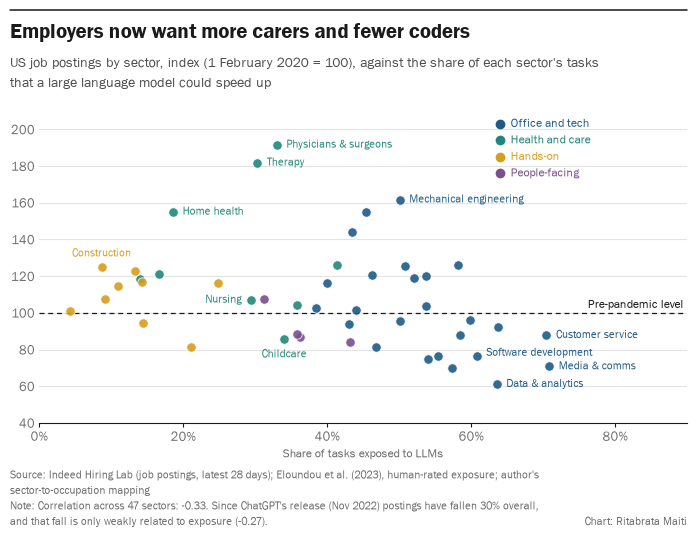

In [11]:
postings = ds.indeed_sectors()
total = ds.indeed_total()
last_day = postings.date.max()
window = postings[postings.date > last_day - pd.Timedelta(days=28)].groupby("sector")["index"].mean()
nov22 = postings[(postings.date >= "2022-11-01") & (postings.date < "2022-12-01")].groupby("sector")["index"].mean()
jobs = ds.sector_exposure().set_index("sector").join(window.rename("postings")).join(nov22.rename("nov22"))
jobs["change_since_chatgpt"] = (jobs.postings / jobs.nov22 - 1) * 100
jobs.round(3).to_csv(ds.PROCESSED / "postings_vs_exposure.csv")
r_level = jobs.exposure_human.corr(jobs.postings)
r_change = jobs.exposure_human.corr(jobs.change_since_chatgpt)
total_now = total[total.date > last_day - pd.Timedelta(days=28)]["index"].mean()
total_nov22 = total[(total.date >= "2022-11-01") & (total.date < "2022-12-01")]["index"].mean()
facts("postings_total_latest", total_now, f"Indeed US postings index, all jobs, 28 days to {last_day:%d %b %Y} (Feb 2020 = 100)", "Indeed Hiring Lab", "{:.0f}")
facts("postings_total_change_since_chatgpt", (total_now / total_nov22 - 1) * 100, "change in all US postings since Nov 2022, %", "Indeed Hiring Lab", "{:+.0f}%")
for sector in ("Software Development", "Data & Analytics", "Media & Communications", "Customer Service", "Nursing",
               "Personal Care & Home Health", "Physicians & Surgeons", "Therapy", "Childcare"):
    key = sector.lower().replace(" & ", "_").replace(" ", "_").replace(",", "")
    facts(f"postings_{key}", jobs.loc[sector, "postings"], f"Indeed postings index, {sector} (Feb 2020 = 100)", "Indeed Hiring Lab", "{:.0f}")
for group, value in jobs.groupby("group")["postings"].median().items():
    facts(f"postings_median_{group.replace(' ', '_')}", value, f"median postings index across {group} sectors (Feb 2020 = 100)", "Indeed Hiring Lab; author's grouping", "{:.0f}")
facts("corr_exposure_vs_level", r_level, "correlation across 47 sectors: AI exposure vs postings level", "Indeed; Eloundou et al. 2023; author's calculation")
facts("corr_exposure_vs_change_since_chatgpt", r_change, "correlation: AI exposure vs change in postings since Nov 2022", "Indeed; Eloundou et al. 2023; author's calculation")

GROUP_COLORS = {"office and tech": st.BLUE, "health and care": st.TEAL, "hands-on": st.GOLD, "people-facing": st.PURPLE}
fig, ax = st.new_figure(
    "Employers now want more carers and fewer coders",
    "US job postings by sector, index (1 February 2020 = 100), against the share of each sector's tasks that a "
    "large language model could speed up",
    "Indeed Hiring Lab (job postings, latest 28 days); Eloundou et al. (2023), human-rated exposure; author's "
    "sector-to-occupation mapping",
    note=f"Correlation across 47 sectors: {r_level:.2f}. Since ChatGPT's release (Nov 2022) postings have fallen "
         f"{abs((total_now / total_nov22 - 1) * 100):.0f}% overall, and that fall is only weakly related to "
         f"exposure ({r_change:.2f}).",
    height=5.4)
ax.axhline(100, color=st.INK, lw=0.9, ls=(0, (4, 3)), zorder=1)
ax.text(0.895, 101.5, "Pre-pandemic level", fontsize=8.3, color=st.INK, va="bottom", ha="right")
for group, color in GROUP_COLORS.items():
    g = jobs[jobs.group == group]
    ax.scatter(g.exposure_human, g.postings, s=46, color=color, alpha=0.9, edgecolor="white", lw=0.6, zorder=3)
LABELS = {  # sector: (dx, dy in points, horizontal alignment)
    "Software Development": (7, 2, "left"), "Data & Analytics": (7, 0, "left"), "Media & Communications": (7, 0, "left"),
    "Customer Service": (7, 0, "left"), "Physicians & Surgeons": (7, 0, "left"), "Therapy": (7, 0, "left"),
    "Personal Care & Home Health": (7, 0, "left"), "Nursing": (-7, 0, "right"), "Construction": (0, 10, "center"),
    "Childcare": (0, -11, "center"), "Mechanical Engineering": (7, 0, "left")}
SHORT_SECTOR = {"Personal Care & Home Health": "Home health", "Media & Communications": "Media & comms",
                "Software Development": "Software development", "Data & Analytics": "Data & analytics",
                "Customer Service": "Customer service", "Physicians & Surgeons": "Physicians & surgeons",
                "Mechanical Engineering": "Mechanical engineering"}
for sector, (dx, dy, ha) in LABELS.items():
    r = jobs.loc[sector]
    ax.annotate(SHORT_SECTOR.get(sector, sector), (r.exposure_human, r.postings), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va="center", fontsize=8.2, color=GROUP_COLORS[r.group])
ax.set_xlim(0, 0.9)
ax.set_ylim(40, 210)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
for i, (group, color) in enumerate(GROUP_COLORS.items()):
    ax.scatter([0.64], [203 - i * 9], s=36, color=color)
    ax.text(0.655, 203 - i * 9, group.capitalize(), va="center", fontsize=8.5, color=color)
ax.set_xlabel("Share of tasks exposed to LLMs", fontsize=8.8)
st.polish(ax)
st.save(fig, "08_postings_vs_exposure")

## 9. When people have children

Births per 1,000 women by age group, 1990 and 2023 (UN estimates). If AI lengthens the stretch between
graduation and a secure job, this is the age range it touches.

births_25_29_change_kor                        -87%   change in births per 1,000 women aged 25-29, South Korea, 1990-2023
births_under30_share_2023_kor                   18%   share of the TFR from births before 30, South Korea, 2023
mean_age_childbearing_2023_kor                 33.4   mean age at childbearing, South Korea, 2023
mean_age_childbearing_1990_kor                 27.2   mean age at childbearing, South Korea, 1990
births_25_29_change_jpn                        -52%   change in births per 1,000 women aged 25-29, Japan, 1990-2023
births_under30_share_2023_jpn                   36%   share of the TFR from births before 30, Japan, 2023
mean_age_childbearing_2023_jpn                 31.9   mean age at childbearing, Japan, 2023
mean_age_childbearing_1990_jpn                 29.0   mean age at childbearing, Japan, 1990
births_25_29_change_ita                        -42%   change in births per 1,000 women aged 25-29, Italy, 1990-2023
births_under30_share_2023_ita                   

WindowsPath('C:/Projects/TinTin/drafts/demography-ai/analysis/figures/09_births_by_age.png')

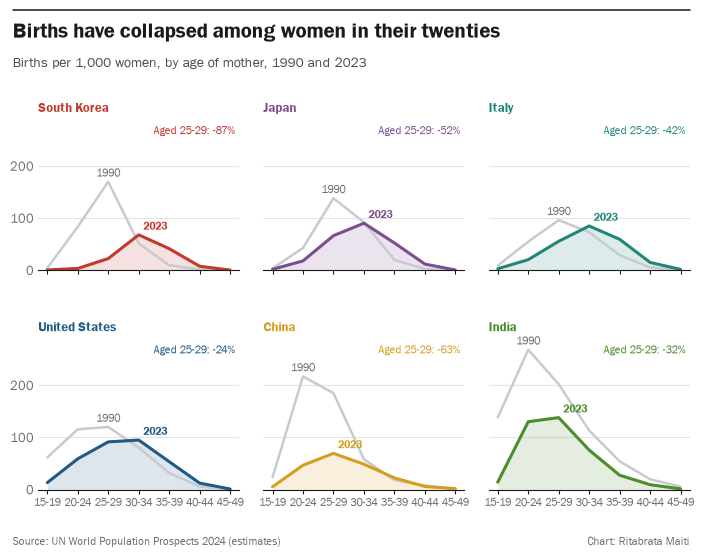

In [12]:
asfr = ds.wpp_asfr()
mac = ind[ind.year.isin([1990, LAST])].pivot(index="iso3", columns="year", values="mac")
PANELS = ["KOR", "JPN", "ITA", "USA", "CHN", "IND"]
AGES = ["15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49"]
for iso in PANELS:
    t = asfr[(asfr.iso3 == iso) & asfr.year.isin([1990, LAST])].pivot(index="age_group", columns="year", values="asfr")
    facts(f"births_25_29_change_{iso.lower()}", (t.loc["25-29", LAST] / t.loc["25-29", 1990] - 1) * 100,
          f"change in births per 1,000 women aged 25-29, {NAMES[iso]}, 1990-{LAST}", UN, "{:+.0f}%")
    facts(f"births_under30_share_{LAST}_{iso.lower()}", t.loc[["15-19", "20-24", "25-29"], LAST].sum() / t[LAST].sum() * 100,
          f"share of the TFR from births before 30, {NAMES[iso]}, {LAST}", UN, "{:.0f}%")
    facts(f"mean_age_childbearing_{LAST}_{iso.lower()}", mac.loc[iso, LAST], f"mean age at childbearing, {NAMES[iso]}, {LAST}", UN, "{:.1f}")
    facts(f"mean_age_childbearing_1990_{iso.lower()}", mac.loc[iso, 1990], f"mean age at childbearing, {NAMES[iso]}, 1990", UN, "{:.1f}")

fig, axes = st.new_figure(
    "Births have collapsed among women in their twenties",
    f"Births per 1,000 women, by age of mother, 1990 and {LAST}",
    f"{UN} (estimates)",
    nrows=2, ncols=3, height=5.6, sharex=True, sharey=True, hspace=0.45, wspace=0.12, left=0.07, top_pad=0.42)
x = np.arange(len(AGES))
for ax, iso in zip(axes.flat, PANELS):
    t = asfr[(asfr.iso3 == iso) & asfr.year.isin([1990, LAST])].pivot(index="age_group", columns="year", values="asfr").loc[AGES]
    color = st.COUNTRY_COLORS[iso]
    ax.fill_between(x, t[LAST], color=color, alpha=0.15, lw=0)
    ax.plot(x, t[1990], color=st.CONTEXT, lw=1.8)
    ax.plot(x, t[LAST], color=color, lw=2.2)
    peak90 = int(np.argmax(t[1990].values))
    ax.text(peak90, t[1990].iloc[peak90] + 10, "1990", ha="center", fontsize=7.8, color=st.MUTED)
    peak23 = int(np.argmax(t[LAST].values))
    ax.text(peak23 + 0.15, t[LAST].iloc[peak23] + 10, str(LAST), ha="left", fontsize=7.8, color=color, **st.BOLD)
    change = (t.loc["25-29", LAST] / t.loc["25-29", 1990] - 1) * 100
    ax.text(0.98, 0.9, f"Aged 25-29: {change:+.0f}%", transform=ax.transAxes, ha="right", fontsize=8.2, color=color)
    st.panel_title(ax, NAMES[iso], color=color, size=9.5)
    ax.set_xticks(x, AGES, fontsize=7.6)
    ax.set_ylim(0, 290)
    ax.yaxis.set_major_locator(MultipleLocator(100))
    st.polish(ax)
st.save(fig, "09_births_by_age")

## Numbers for the text

Every figure the essay quotes, with its source, is written to `numbers.md` and `numbers.json`.

In [13]:
path = facts.write(HERE)
print(f"wrote {path.name} ({len(facts.items)} numbers) and {len(list(st.FIGURES.glob('*.png')))} charts in figures/")

wrote numbers.md (214 numbers) and 9 charts in figures/
